In [30]:
import anndata as ad 
import scanpy as sc 
import os
import pandas as pd 
import numpy as np
import decoupler as dc 

import gseapy as gp

from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats
import matplotlib.pyplot as plt 

#### Load ML model


In [31]:
import pickle 

with open('../../models/pb_notebook_model.pkl', 'rb') as file:
    ven_model = pickle.load(file)

#### Load Data

In [32]:
os.listdir('../../data/Leblay_Single_Cell/GSE199359_RAW/')

['GSM5971018_P1498_Pre_filtered_feature_bc_matrix.h5',
 'GSM5971019_P1393_Pre_filtered_feature_bc_matrix.h5',
 'GSM5971020_P1217_Pre_filtered_feature_bc_matrix.h5',
 'GSM5971021_P1389_Pre_filtered_feature_bc_matrix.h5',
 'GSM5971022_P1627_Post_filtered_feature_bc_matrix.h5',
 'GSM5971023_P1555_Post_filtered_feature_bc_matrix.h5',
 'GSM5971024_P1438_Post_filtered_feature_bc_matrix.h5',
 'GSM5971025_P1479_Post_filtered_feature_bc_matrix.h5',
 'GSM7040843_P1723_Pre_filtered_feature_bc_matrix.h5',
 'GSM7040844_P1608_Pre_filtered_feature_bc_matrix.h5',
 'GSM7040845_P1675_Post_filtered_feature_bc_matrix.h5',
 'GSM7040846_P1299_Pre_filtered_feature_bc_matrix.h5',
 'GSM7040847_P1345_Post_filtered_feature_bc_matrix.h5',
 'GSM7040848_P1643_Pre_filtered_feature_bc_matrix.h5',
 'GSM7040849_P1752_Pre_filtered_feature_bc_matrix.h5',
 'GSM7040850_P1680_Pre_filtered_feature_bc_matrix.h5',
 'GSM7040851_P1388_Pre_filtered_feature_bc_matrix.h5',
 'GSM7040852_P1751_Pre_filtered_feature_bc_matrix.h5',
 'GS

In [33]:
adatas = {}

os.listdir('../../data/Leblay_Single_Cell/GSE199359_RAW/')

for file_name in os.listdir('../../data/Leblay_Single_Cell/GSE199359_RAW/'):
    adata = sc.read_10x_h5('../../data/Leblay_Single_Cell/GSE199359_RAW/' + file_name) 
    adata.var_names_make_unique()
    treatment_status_str = file_name[17:21].replace('_', "")
    treatment_status = [treatment_status_str for i in range(len(adata.obs))]
    adata.obs['treatment_status'] = treatment_status
    print(treatment_status_str)
    adatas[file_name[11: 16]] = adata

adata = ad.concat(adatas, label='sample')




/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


Pre


/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


Pre


/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


...

/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


Pre


/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


Post
Pre


/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/tmp/ipykernel_9964/2209338613.py:14: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = ad.concat(adatas, label='sample')


In [34]:
metadata = pd.read_csv("../../data/Leblay_Single_Cell/metadata.csv", sep='\t').set_index('Patient ID')


In [35]:
metadata['t11_14'] = [False if metadata.loc[p]['t(11;14) status'] == 'Negative' else True for p in metadata.index]
metadata

,Sex,Age (y),MM subtype,t(11;14) status,t(4;14) status,t(14;16) status,del13q status,del17p status,Stage (R-ISS),Number of prior therapies,Best response to venetoclax,Duration of response to venetoclax (mo),Prevenetoclax Sample,Postvenetoclax Sample,DNA_SEQ_Prevenetoclax Sample,DNA_SEQ_Postvenetoclax Sample,t11_14
Patient ID,,,,,,,,,,,,,,,,,
PM01,M,44,IgGκ,Positive (17% of the cells),Negative,Negative,Negative,Negative,II,4,VGPR,8.0,P1393,P1555,P1426,P1555,True
PM02,M,74,IgGκ,Negative,Negative,Negative,Negative,Negative,I,7,NaN,NaN,P1723,NaN,NaN,NaN,False
PM03,F,66,κ light chain,Negative,Negative,Negative,Negative,Negative,III,4,NaN,NaN,P1608,P1675,NaN,NaN,False
PM04,F,82,IgGκ,Negative,Negative,Negative,Negative,Negative,II,3,NaN,NaN,P1299,P1345,NaN,NaN,False
PM05,M,78,Λ light chain,Positive (97% of the cells),Negative,Negative,Negative,Positive (99% of cells),II,8,VGPR,21.0,P1643,NaN,NaN,NaN,True
PM06,M,65,IgGκ,Negative,Negative,Negative,Negative,Negative,III,4,NaN,NaN,P1752,NaN,NaN,NaN,False
PM07,M,69,IgGλ,Positive (88% of the cells),Negative,Negative,Negative,Positive (66% of cells),I,4,PR,4.0,P1389,P1479,P1389,P1479,True
PM08,M,60,IgAκ,Negative,Positive (17% of the cells),Negative,Negative,Negative,II,6,NaN,NaN,P1680,NaN,NaN,NaN,False
PM09,M,74,IgGλ,Positive (77% of the cells),Negative,Negative,Negative,Negative,I,4,VGPR,13.0,P1498,P1698,P1498,P1698,True


In [36]:
pre_ven_mapper = pd.Series(dict(zip(metadata['Prevenetoclax Sample'],metadata.index)))
post_ven_mapper = pd.Series(dict(zip(metadata['Postvenetoclax Sample'],metadata.index)))

mapper = pd.concat((pre_ven_mapper, post_ven_mapper))



#mapper_index_corrected = ['P1722' if mapper.loc[index] == 'PM15' else index for index in mapper.index]
#mapper.index = mapper_index_corrected

# need to remove P1627
adata = adata[adata.obs['sample'] != "P1627"].copy()


/tmp/ipykernel_9964/3191152140.py:12: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = adata[adata.obs['sample'] != "P1627"].copy()


In [37]:
mapper

P1393    PM01
P1723    PM02
P1608    PM03
P1299    PM04
P1643    PM05
P1752    PM06
P1389    PM07
P1680    PM08
P1498    PM09
P1217    PM10
P1388    PM11
P1751    PM12
P1396    PM13
P1395    PM14
P1722    PM15
P1555    PM01
NaN      PM15
P1675    PM03
P1345    PM04
P1479    PM07
P1698    PM09
P1438    PM10
P1809    PM12
P1461    PM13
P1606    PM14
dtype: str

In [38]:
patient_id = []
for sample_id in adata.obs['sample']:
    patient_id.append(mapper.loc[sample_id])

adata.obs['patient_id'] = patient_id

In [39]:
t11_14 = []

for patient_id in adata.obs['patient_id']:
    t11_14.append(metadata.loc[patient_id]['t11_14'])

adata.obs['t11_14'] = t11_14

In [40]:
adata.obs

,treatment_status,sample,patient_id,t11_14
AAACCTGTCACAACGT-1,Pre,P1498,PM09,True
AAACGGGAGGCTCATT-1,Pre,P1498,PM09,True
AAAGCAAAGCCCAATT-1,Pre,P1498,PM09,True
AAAGCAATCTCTTGAT-1,Pre,P1498,PM09,True
AAAGTAGGTTCGGCAC-1,Pre,P1498,PM09,True
...,...,...,...,...
TTTGTTGCACGACGAA-1,Pre,P1722,PM15,False
TTTGTTGCAGCGTATT-1,Pre,P1722,PM15,False
TTTGTTGGTAATGCTC-1,Pre,P1722,PM15,False
TTTGTTGTCCGGCTTT-1,Pre,P1722,PM15,False


#### Quality Control


In [41]:
adata.var['mt'] = adata.var_names.str.startswith("MT-")
adata.var['ribo'] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var['hb'] = adata.var_names.str.contains("^HB[^(P)]")

In [42]:
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo', 'hb'], inplace=True, log1p=True)

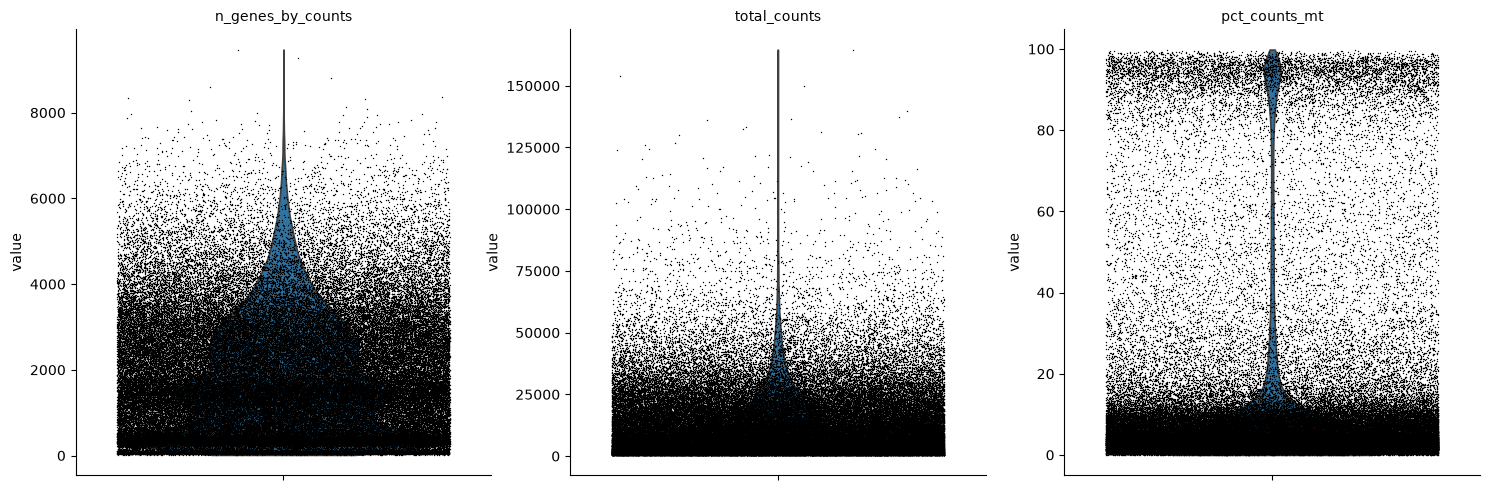

In [43]:
sc.pl.violin(adata,['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

In [44]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata,min_cells=3)
adata = adata[adata.obs['pct_counts_mt'] < 15].copy()



/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:164: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata._inplace_subset_obs(cell_subset)
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:164: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata._inplace_subset_obs(cell_subset)
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:281: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata._inplace_subset_var(gene_subset)
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:281: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique

In [45]:
#sc.pp.scrublet(adata, batch_key='sample')

In [46]:
#print(f'Number of predicted doublets: {len(adata.obs[adata.obs['predicted_doublet'] == True])}')
#adata = adata[adata.obs['predicted_doublet'] == False]

In [47]:
adata.obs_names_make_unique()
pdata = dc.pp.pseudobulk(
    adata = adata,
    sample_col='patient_id', 
    groups_col='treatment_status',
    mode='sum',
    skip_checks=True,

)

In [48]:
pdata.obs

,patient_id,treatment_status,sample,t11_14,psbulk_cells,psbulk_counts
PM01_Post,PM01,Post,P1555,True,4880.0,65727135.0
PM02_Post,PM02,Post,P1723,False,0.0,0.0
PM03_Post,PM03,Post,P1675,False,3163.0,81882672.0
PM04_Post,PM04,Post,P1345,False,1751.0,19237557.0
PM05_Post,PM05,Post,P1643,True,0.0,0.0
PM06_Post,PM06,Post,P1752,False,0.0,0.0
PM07_Post,PM07,Post,P1479,True,4391.0,28393286.0
PM08_Post,PM08,Post,P1680,False,0.0,0.0
PM09_Post,PM09,Post,P1498,True,0.0,0.0
PM10_Post,PM10,Post,P1438,True,13671.0,24310802.0


In [49]:
# get pseudobulk features
pseudobulk_features = pdata.var_names

with open('../../outputs/pseudobulk_features.txt', 'w') as file:
    for line in list(pseudobulk_features):
        file.write(f'{line}\n')

#pdata = pdata[:,list( set(pdata.var_names) & set(ven_model.feature_names_in_))]

In [50]:
pdata = pdata[:, ven_model.feature_names_in_]

In [51]:
pdata.obs['y_pred'] = ven_model.predict(pdata.to_df())
pdata.obs['y_prob'] = ven_model.predict_proba(pdata.to_df())[:,1]



/tmp/ipykernel_9964/3356069138.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  pdata.obs['y_pred'] = ven_model.predict(pdata.to_df())


Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/pydeseq2/dds.py:539: UserWarning: Every gene contains at least one zero, cannot compute log geometric means. Switching to iterative mode.
  self.fit_size_factors(
Fitting dispersions...
... done in 2.65 seconds.

Fitting MAP dispersions...
... done in 2.64 seconds.

Fitting dispersions...
... done in 2.55 seconds.

Fitting MAP dispersions...
... done in 2.82 seconds.

Fitting dispersions...
... done in 2.88 seconds.

Fitting MAP dispersions...
... done in 2.92 seconds.

Fitting dispersions...
... done in 3.25 seconds.

Fitting MAP dispersions...
... done in 2.94 seconds.

Fitting dispersions...
... done in 3.84 seconds.

Fitting MAP dispersions...
... done in 2.91 seconds.

Fitting dispersions...
... done in 4.30 seconds.

Fitting MAP dispersions...
... done in 2.90 seconds.

Fitting dispersions...
... done in 4.47 seconds.

Fitting MAP dispersions...
... done in 2.91 seconds.

F

Log2 fold change & Wald test p-value: y_pred 1 vs 0
           baseMean  log2FoldChange     lfcSE       stat        pvalue  \
HSD11B1L   1.413206      -17.385443  1.330485 -13.066995  5.083445e-39   
SYTL4      0.089671      -21.536983  1.447699 -14.876705  4.669385e-50   
GRK6      23.957496      -13.293560  1.306895 -10.171863  2.647957e-24   
NDUFA2    65.923619      -11.833798  1.278166  -9.258422  2.074759e-20   
PSMD8     66.928493      -11.811773  1.270718  -9.295354  1.467168e-20   
...             ...             ...       ...        ...           ...   
PFAS       1.273407      -17.523398  1.271832 -13.778074  3.453646e-43   
RALGAPB    2.230715      -16.714621  1.272748 -13.132700  2.138921e-39   
GABARAP    4.517082      -15.710241  1.391082 -11.293539  1.412338e-29   
CD1D       5.736426      -15.358548  1.439031 -10.672840  1.363926e-26   
SYF2      29.112031      -13.014018  1.270486 -10.243338  1.267846e-24   

                  padj  
HSD11B1L  1.300868e-38  
SYTL4    

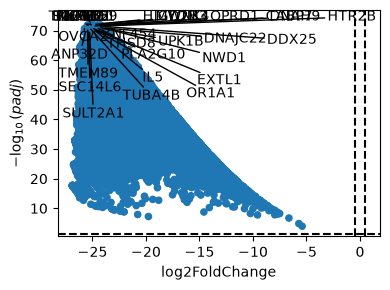

In [52]:

expr_df = pd.DataFrame(pdata.to_df(), columns=np.array(pdata.var_names))

    

inference = DefaultInference(n_cpus=8)
        

dds = DeseqDataSet(counts = expr_df, metadata=pd.DataFrame(pdata.obs), design="~y_pred", refit_cooks=True, inference=inference) 
dds.deseq2()

ds_res = DeseqStats(dds, contrast=["y_pred", 1, 0], inference=inference)
ds_res.summary()        

ds_res = ds_res.results_df
   
    
ds_res= ds_res.sort_values(by="padj", ascending=False)

dc.pl.volcano(data=ds_res, x="log2FoldChange", y="padj", top=30)
#plt.show()

    #ds_res = ds_res[ds_res['padj'] < 0.05]
    #ds_res = ds_res[(abs(ds_res['log2FoldChange']) >= 2)]

  

In [54]:
results_df = ds_res


In [55]:
results_df

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
JCHAIN,5674.375470,-5.406408,1.397523,-3.868563,1.094785e-04,1.094785e-04
B2M,4589.423795,-5.712560,1.314505,-4.345788,1.387768e-05,1.387854e-05
EEF1A1,2412.374284,-6.640405,1.274828,-5.208863,1.900009e-07,1.900243e-07
FOXR1,0.269640,-19.770323,3.646558,-5.421640,5.905481e-08,5.906574e-08
HBB,315.511868,-9.575132,1.698172,-5.638492,1.715456e-08,1.715879e-08
...,...,...,...,...,...,...
CRISP3,0.000000,0.000000,0.000000,0.000000,NaN,NaN
CSN2,0.000000,0.000000,0.000000,0.000000,NaN,NaN
TSPY3,0.000000,0.000000,0.000000,0.000000,NaN,NaN
KRT20,0.000000,0.000000,0.000000,0.000000,NaN,NaN


2026-10-08 10:53:07,276 [WARNING] Input data contains NA, filled NA with 0
2026-10-08 10:53:07,281 [WARNING] Duplicated values found in preranked stats:
sample	ratio
baseMean         0.45%
log2FoldChange   0.45%
lfcSE            0.45%
stat             0.45%
pvalue           0.45%
padj             4.57%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'Predicted Sensitive vs. Resistant'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

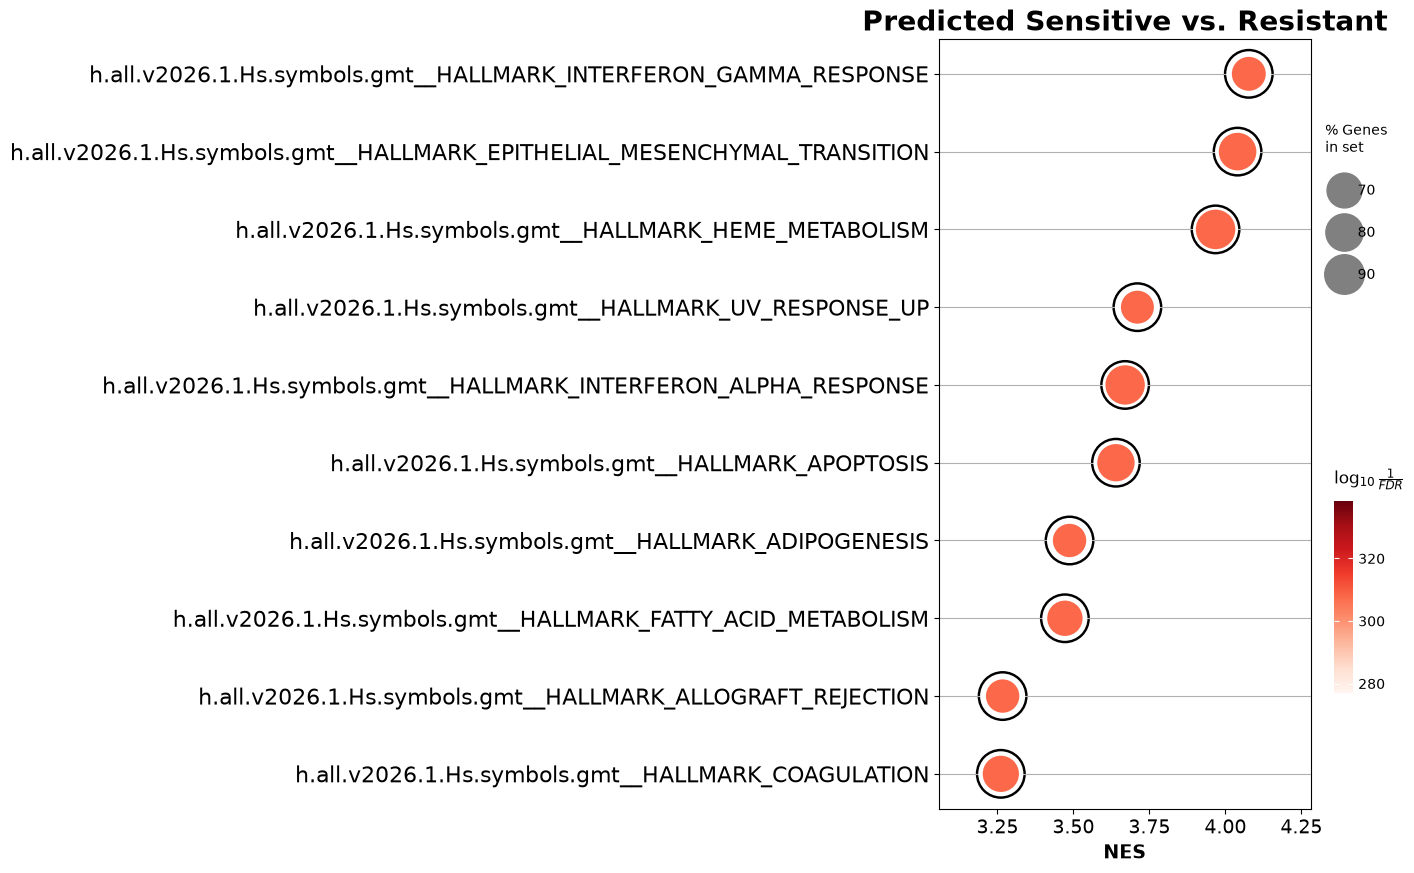

In [56]:

# GSEA
plt.clf()
gmt_dir = "../../data/GMT/"
hallmark_gmt = gmt_dir + "h.all.v2026.1.Hs.symbols.gmt"
#gmt = gmt_dir+"msigdb.v2026.1.Hs.symbols.gmt"
#gene_set_path = gmt_dir + 'GO_Biological_Process_2026.json'

#with open(gene_set_path, 'r') as f:
#    gene_set = json.load(f)

results_df = results_df.sort_values(by="stat")
pre_res = gp.prerank(rnk=results_df, gene_sets=[hallmark_gmt], threads=8, min_size=5, max_size=1000, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")
#pre_res.res2d["Term"] = (
#    pre_res.res2d["Term"]
    #.str.replace("h.all.v2026.1.Hs.symbols.gmt__HALLMARK_", "", regex=False)
#)


pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='Predicted Sensitive vs. Resistant', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True,)
